# Employee Attrition Risk Explorer
**A People Analytics + AI consulting mini-case — Ryan Le** (UNC Kenan-Flagler, BSBA Business Administration + Data Science)

**Business question:** Which employees are most likely to leave, why, and what should the company do about it?

**Plan**
1. **Explore** the data (EDA) to find the biggest attrition drivers: overtime, income, tenure, job satisfaction, business travel.
2. **Predict** attrition with two models (logistic regression and random forest) and compare them.
3. **Recommend** 3–4 retention actions, framed like a product owner would (user → problem → metric), with estimated impact.

> **Data note:** This uses IBM's public *HR Analytics Employee Attrition & Performance* sample dataset (1,470 rows, 35 columns).
> The employees are **fictional** — the data was created by IBM data scientists for teaching and demos. Results show the *method*, not facts about a real company.
> Source: IBM's GitHub repo [`IBM/employee-attrition-aif360`](https://github.com/IBM/employee-attrition-aif360) → `data/emp_attrition.csv`
> (raw: https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv). The same data is widely shared on Kaggle as `WA_Fn-UseC_-HR-Employee-Attrition.csv`.


## 0. Setup

In [1]:
# Core libraries: pandas for tables, matplotlib for charts, scikit-learn for models
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score, precision_score, roc_curve

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#2b6cb0", "#c53030", "#a0aec0"
os.makedirs("figures", exist_ok=True)   # charts are also saved as PNGs for the PDF summary


In [2]:
# Load the CSV. It sits next to this notebook; if it's missing (e.g., in Colab), download it from IBM's GitHub.
LOCAL = "IBM_HR_Employee_Attrition.csv"
URL = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Quick data quality check: missing values, and columns that never change (useless for analysis)
print("Missing values in whole table:", int(df.isna().sum().sum()))
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns (dropped):", constant_cols)

# Drop constant columns and the ID column (an ID number has no predictive meaning)
df = df.drop(columns=constant_cols + ["EmployeeNumber"])

# Make a 0/1 target column: 1 = employee left
df["Left"] = (df["Attrition"] == "Yes").astype(int)
overall_rate = df["Left"].mean()
print(f"Employees: {len(df):,} | Left: {df['Left'].sum()} | Overall attrition rate: {overall_rate:.1%}")

Missing values in whole table: 0
Constant columns (dropped): ['EmployeeCount', 'Over18', 'StandardHours']
Employees: 1,470 | Left: 237 | Overall attrition rate: 16.1%


## 1. Exploratory Data Analysis — what drives attrition?
For each driver I compare the **attrition rate** (share of employees in a group who left) against the overall rate (dashed line).

In [4]:
def rate_by(col, order=None):
    """Attrition rate and headcount for each value of `col`."""
    t = df.groupby(col)["Left"].agg(rate="mean", n="size")
    return t.reindex(order) if order is not None else t

def bar_chart(table, title, xlabel, fname, highlight=None):
    """Bar chart of attrition rate by group, with the overall rate as a dashed line."""
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    colors = [RED if (highlight is not None and i in highlight) else BLUE for i in range(len(table))]
    bars = ax.bar(table.index.astype(str), table["rate"], color=colors)
    for b, (r, n) in zip(bars, zip(table["rate"], table["n"])):
        ax.text(b.get_x() + b.get_width()/2, r + 0.005, f"{r:.0%}\n(n={n})", ha="center", va="bottom", fontsize=8)
    ax.axhline(overall_rate, ls="--", color=GREY, label=f"Overall {overall_rate:.1%}")
    ax.set_ylim(0, max(table["rate"]) * 1.35)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(xlabel); ax.set_ylabel("Attrition rate")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    fig.tight_layout(); fig.savefig(f"figures/{fname}.png", dpi=200); plt.show()

### Chart 1 — Overtime

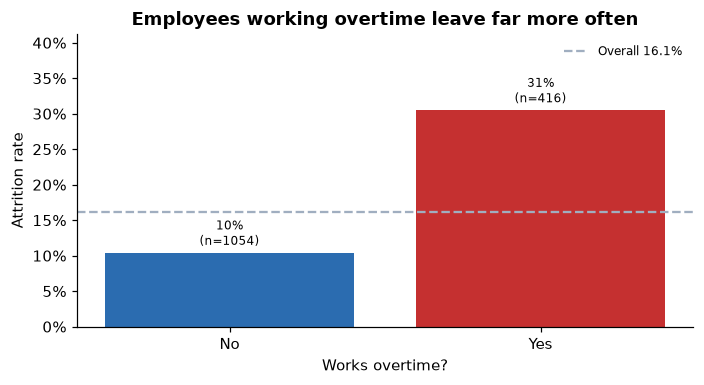

Overtime: 30.5% vs no overtime: 10.4% -> 2.9x higher


In [5]:
ot = rate_by("OverTime", ["No", "Yes"])
bar_chart(ot, "Employees working overtime leave far more often", "Works overtime?", "1_overtime", highlight=[1])
ot_ratio = ot.loc["Yes", "rate"] / ot.loc["No", "rate"]
print(f"Overtime: {ot.loc['Yes','rate']:.1%} vs no overtime: {ot.loc['No','rate']:.1%} -> {ot_ratio:.1f}x higher")

### Chart 2 — Monthly income

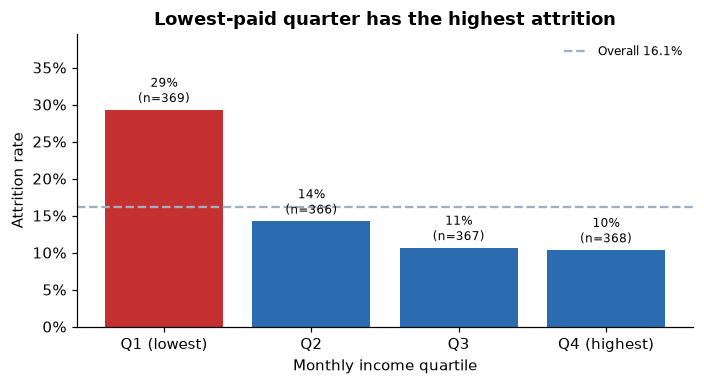

Income quartile cut-offs ($/month): [2911.0, 4919.0, 8379.0]
Median income — stayed: $5,204 | left: $3,202


In [6]:
# Split income into 4 equal-sized groups (quartiles)
df["IncomeQuartile"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
inc = rate_by("IncomeQuartile")
bar_chart(inc, "Lowest-paid quarter has the highest attrition", "Monthly income quartile", "2_income", highlight=[0])
print("Income quartile cut-offs ($/month):", df["MonthlyIncome"].quantile([.25, .5, .75]).round(0).tolist())
print(f"Median income — stayed: ${df[df.Left==0].MonthlyIncome.median():,.0f} | left: ${df[df.Left==1].MonthlyIncome.median():,.0f}")

### Chart 3 — Tenure (years at company)

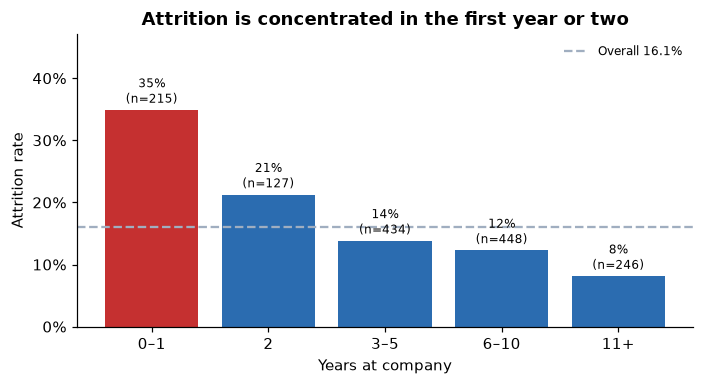

In [7]:
bins = [-1, 1, 2, 5, 10, 40]
labels = ["0–1", "2", "3–5", "6–10", "11+"]
df["TenureBand"] = pd.cut(df["YearsAtCompany"], bins=bins, labels=labels)
ten = rate_by("TenureBand")
bar_chart(ten, "Attrition is concentrated in the first year or two", "Years at company", "3_tenure", highlight=[0])

### Chart 4 — Job satisfaction

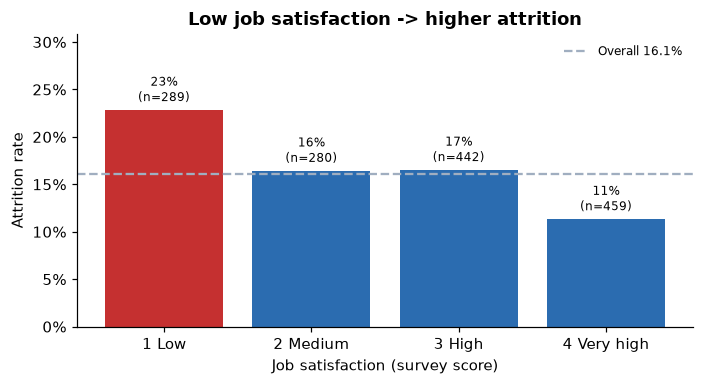

In [8]:
sat_labels = {1: "1 Low", 2: "2 Medium", 3: "3 High", 4: "4 Very high"}
df["JobSatLabel"] = df["JobSatisfaction"].map(sat_labels)
sat = rate_by("JobSatLabel", list(sat_labels.values()))
bar_chart(sat, "Low job satisfaction -> higher attrition", "Job satisfaction (survey score)", "4_satisfaction", highlight=[0])

### Chart 5 — Business travel

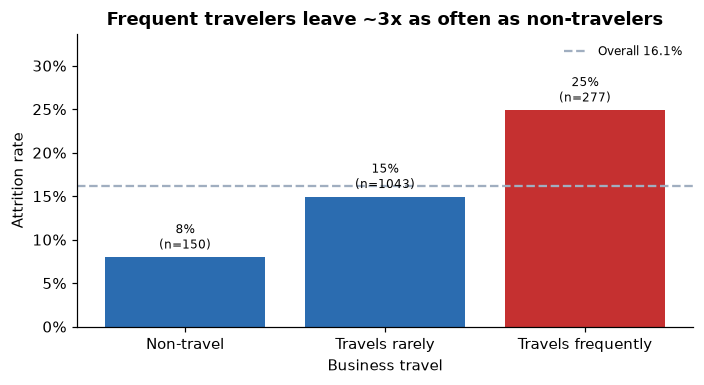

In [9]:
trav = rate_by("BusinessTravel", ["Non-Travel", "Travel_Rarely", "Travel_Frequently"])
trav.index = ["Non-travel", "Travels rarely", "Travels frequently"]
bar_chart(trav, "Frequent travelers leave ~3x as often as non-travelers", "Business travel", "5_travel", highlight=[2])

### Chart 6 — Stacking risk factors

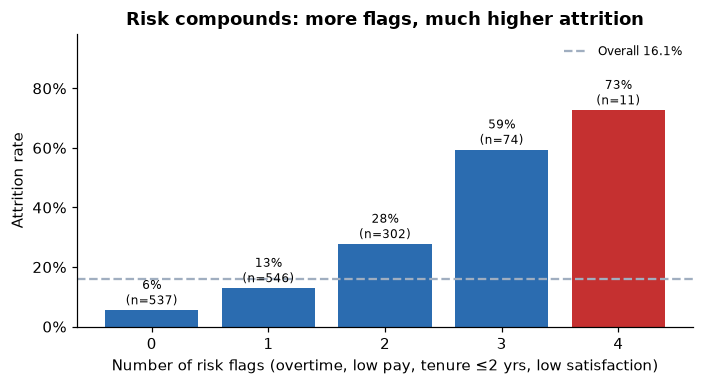

In [10]:
# How do drivers combine? Count how many of 4 'risk flags' each employee has.
df["flag_overtime"] = (df["OverTime"] == "Yes").astype(int)
df["flag_low_income"] = (df["IncomeQuartile"] == "Q1 (lowest)").astype(int)
df["flag_new"] = (df["YearsAtCompany"] <= 2).astype(int)
df["flag_low_sat"] = (df["JobSatisfaction"] == 1).astype(int)
df["RiskFlags"] = df[["flag_overtime", "flag_low_income", "flag_new", "flag_low_sat"]].sum(axis=1)
flags = rate_by("RiskFlags")
bar_chart(flags, "Risk compounds: more flags, much higher attrition", "Number of risk flags (overtime, low pay, tenure ≤2 yrs, low satisfaction)", "6_flags", highlight=[len(flags)-1])

In [11]:
# One summary table of the EDA findings
summary = pd.DataFrame({
    "Group": ["Overtime", "No overtime", "Lowest income quartile", "Highest income quartile", "Tenure 0–1 yrs",
              "Low job satisfaction (1)", "Very high job satisfaction (4)", "Travels frequently", "Non-travel"],
    "Attrition rate": [ot.loc["Yes","rate"], ot.loc["No","rate"], inc.iloc[0]["rate"], inc.iloc[3]["rate"], ten.iloc[0]["rate"],
                       sat.iloc[0]["rate"], sat.iloc[3]["rate"], trav.iloc[2]["rate"], trav.iloc[0]["rate"]],
})
summary["Attrition rate"] = summary["Attrition rate"].map("{:.1%}".format)
summary

,Group,Attrition rate
0,Overtime,30.5%
1,No overtime,10.4%
2,Lowest income quartile,29.3%
3,Highest income quartile,10.3%
4,Tenure 0–1 yrs,34.9%
5,Low job satisfaction (1),22.8%
6,Very high job satisfaction (4),11.3%
7,Travels frequently,24.9%
8,Non-travel,8.0%


## 2. Predicting attrition — logistic regression vs. random forest
- **Features:** all remaining columns; text categories (e.g., Department) are one-hot encoded into 0/1 columns.
- **Split:** 75% train / 25% test, *stratified* so both sets keep the same ~16% attrition share.
- **Class imbalance:** only ~16% left, so a model that always guesses "stays" would already be ~84% accurate. That's why **recall** (share of real leavers we catch) and **ROC-AUC** (how well the model ranks leavers above stayers; 0.5 = coin flip, 1.0 = perfect) matter more than accuracy. Both models use `class_weight="balanced"` so they pay more attention to leavers.

In [12]:
# Build the feature table (X) and target (y). Drop helper columns I created for EDA.
helper = ["Attrition", "Left", "IncomeQuartile", "TenureBand", "JobSatLabel", "RiskFlags",
          "flag_overtime", "flag_low_income", "flag_new", "flag_low_sat"]
X = pd.get_dummies(df.drop(columns=helper), drop_first=True).astype(float)
y = df["Left"]
print("Feature columns:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows | Test leavers: {y_test.sum()}")
baseline_acc = 1 - y_test.mean()
print(f"Baseline accuracy (always predict 'stays'): {baseline_acc:.1%}")

Feature columns: 44
Train: 1102 rows | Test: 368 rows | Test leavers: 59
Baseline accuracy (always predict 'stays'): 84.0%


In [13]:
# Model 1: Logistic regression (scale features first so coefficients are comparable)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
logreg.fit(X_train, y_train)

# Model 2: Random forest (many decision trees voting together)
forest = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced", random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)

def evaluate(name, model):
    prob = model.predict_proba(X_test)[:, 1]   # predicted probability of leaving
    pred = (prob >= 0.5).astype(int)            # flag as 'at risk' if probability >= 50%
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, prob),
            "Recall (leavers caught)": recall_score(y_test, pred), "Precision": precision_score(y_test, pred)}

results = pd.DataFrame([evaluate("Logistic regression", logreg), evaluate("Random forest", forest)]).set_index("Model")
results.round(3)

,Accuracy,ROC-AUC,Recall (leavers caught),Precision
Model,,,,
Logistic regression,0.777,0.808,0.644,0.384
Random forest,0.834,0.767,0.424,0.481


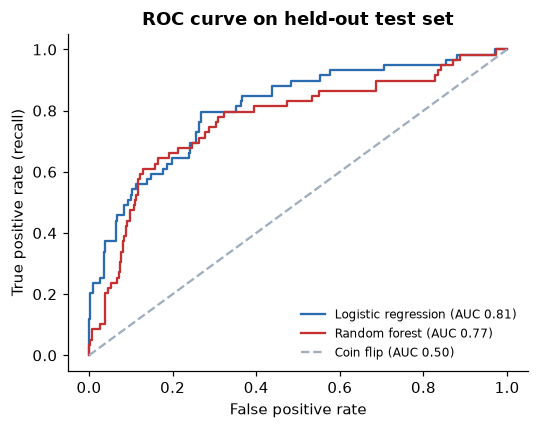

In [14]:
# ROC curves: higher and further left = better ranking of who will leave
fig, ax = plt.subplots(figsize=(5, 4))
for name, model, col in [("Logistic regression", logreg, BLUE), ("Random forest", forest, RED)]:
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {roc_auc_score(y_test, prob):.2f})")
ax.plot([0, 1], [0, 1], ls="--", color=GREY, label="Coin flip (AUC 0.50)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve on held-out test set", fontweight="bold"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("figures/7_roc.png", dpi=200); plt.show()

### Which features matter most?
- **Logistic regression coefficients** (on standardized features): positive = raises leave risk, negative = lowers it. Easy to explain to an HR leader.
- **Random forest importance:** how much each feature helps the trees split leavers from stayers (no direction).

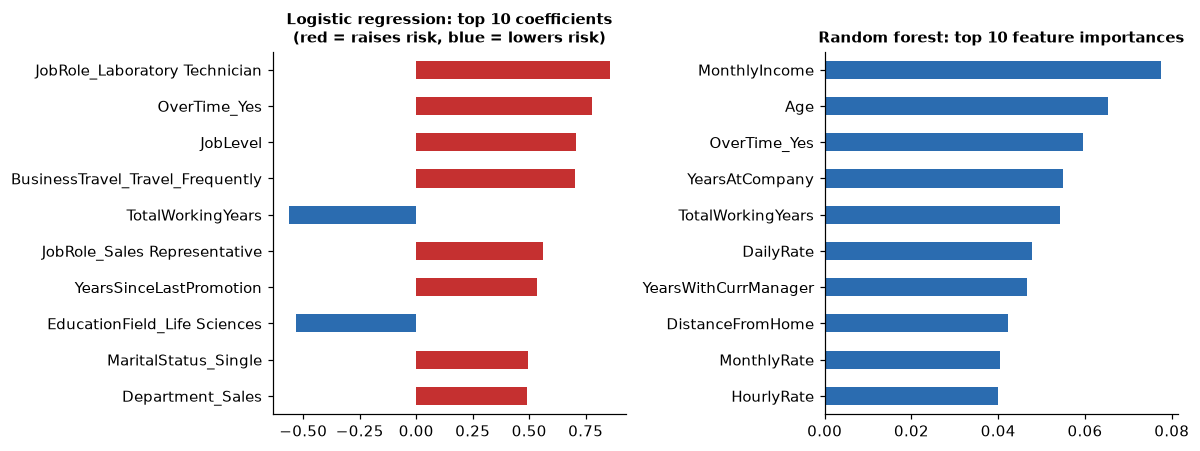

Top logistic-regression drivers:
 JobRole_Laboratory Technician       0.86
OverTime_Yes                        0.78
JobLevel                            0.71
BusinessTravel_Travel_Frequently    0.70
TotalWorkingYears                  -0.56
JobRole_Sales Representative        0.56
YearsSinceLastPromotion             0.53
EducationField_Life Sciences       -0.53
MaritalStatus_Single                0.49
Department_Sales                    0.49


In [15]:
coefs = pd.Series(logreg.named_steps["logisticregression"].coef_[0], index=X.columns)
top_lr = coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:10]
top_rf = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)[:10]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
top_lr[::-1].plot.barh(ax=axes[0], color=[RED if v > 0 else BLUE for v in top_lr[::-1]])
axes[0].set_title("Logistic regression: top 10 coefficients\n(red = raises risk, blue = lowers risk)", fontweight="bold", fontsize=10)
top_rf[::-1].plot.barh(ax=axes[1], color=BLUE)
axes[1].set_title("Random forest: top 10 feature importances", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig("figures/8_importance.png", dpi=200); plt.show()
print("Top logistic-regression drivers:\n", top_lr.round(2).to_string())

**How to read this (and its caveats):** Both models agree that **overtime**, **income/seniority**, and **tenure/experience** matter. Two quirks worth knowing: (1) `JobLevel` gets a *positive* coefficient even though senior people leave less — that's because it overlaps heavily with income and total working years (multicollinearity), so the model "splits" the effect between them; read those features together. (2) The random forest ranks `DailyRate`, `MonthlyRate` and `HourlyRate` fairly high, but these columns don't line up with `MonthlyIncome` in this sample dataset, so they're likely noise the trees picked up — one reason the simpler logistic regression scored a better ROC-AUC here.

### Using the model as a tool: an "at-risk watchlist"
A manager can't act on 1,470 people at once. If HR reviews only the **top 20% highest-risk** employees in the test set, what share of actual leavers does that list catch?

In [16]:
best_name = results["ROC-AUC"].idxmax()
best = logreg if best_name == "Logistic regression" else forest
prob = pd.Series(best.predict_proba(X_test)[:, 1], index=X_test.index)
top20 = prob.sort_values(ascending=False).index[: int(len(prob) * 0.20)]
capture = y_test.loc[top20].sum() / y_test.sum()
hit_rate = y_test.loc[top20].mean()
print(f"Best model by ROC-AUC: {best_name}")
print(f"Top-20% watchlist = {len(top20)} employees; catches {y_test.loc[top20].sum()} of {y_test.sum()} leavers ({capture:.0%}).")
print(f"Attrition rate inside the watchlist: {hit_rate:.0%} vs {y_test.mean():.0%} overall ({hit_rate / y_test.mean():.1f}x).")

Best model by ROC-AUC: Logistic regression
Top-20% watchlist = 73 employees; catches 33 of 59 leavers (56%).
Attrition rate inside the watchlist: 45% vs 16% overall (2.8x).


## 3. Consultant recommendations (product-owner framing)
Below, each recommendation is written as a mini product brief: **user → problem → solution → success metric**, with an *estimated* impact.

**How impact is estimated (simple, transparent assumptions — not results):**
- "If the action closes **half** of the gap between the high-risk group's attrition rate and the comparison group's rate."
- Cost of replacing one employee ≈ **50% of their annual salary** (a common rule-of-thumb; real figures vary widely by role).
- Dataset attrition isn't tied to a specific time window, so impact is "employees retained" on this 1,470-person population.

In [17]:
REPLACE_COST_SHARE = 0.50   # assumption: replacing an employee costs ~50% of annual salary
GAP_CLOSED = 0.50           # assumption: the action closes half the attrition gap

def impact(group_mask, comparison_rate, label):
    g = df[group_mask]
    gap = g["Left"].mean() - comparison_rate
    retained = len(g) * gap * GAP_CLOSED
    savings = retained * g["MonthlyIncome"].median() * 12 * REPLACE_COST_SHARE
    return {"Action": label, "Group size": len(g), "Group attrition": f"{g['Left'].mean():.1%}",
            "Comparison rate": f"{comparison_rate:.1%}", "Est. employees retained": round(retained),
            "Est. replacement cost avoided": f"${savings:,.0f}"}

recs = pd.DataFrame([
    impact(df.OverTime == "Yes", ot.loc["No", "rate"], "1. Overtime guardrails"),
    impact(df.YearsAtCompany <= 2, df[df.YearsAtCompany > 2]["Left"].mean(), "2. First-2-years onboarding & mentor program"),
    impact(df.IncomeQuartile == "Q1 (lowest)", df[df.IncomeQuartile != "Q1 (lowest)"]["Left"].mean(), "3. Pay & career-path review for lowest-paid quarter"),
    impact(df.BusinessTravel == "Travel_Frequently", trav.loc["Non-travel", "rate"], "4. Travel load balancing"),
])
recs  # note: groups overlap, so these impacts should not simply be added together

,Action,Group size,Group attrition,Comparison rate,Est. employees retained,Est. replacement cost avoided
0,1. Overtime guardrails,416,30.5%,10.4%,42,"$1,269,188"
1,2. First-2-years onboarding & mentor program,342,29.8%,12.0%,31,"$534,691"
2,3. Pay & career-path review for lowest-paid qu...,369,29.3%,11.7%,32,"$462,233"
3,4. Travel load balancing,277,24.9%,8.0%,23,"$665,362"


In [18]:
# Print the numbers used in the briefs below
for _, r in recs.iterrows():
    print(f"{r['Action']}: {r['Group size']} people, {r['Group attrition']} attrition vs {r['Comparison rate']} -> "
          f"~{r['Est. employees retained']} retained, ~{r['Est. replacement cost avoided']} avoided")

1. Overtime guardrails: 416 people, 30.5% attrition vs 10.4% -> ~42 retained, ~$1,269,188 avoided
2. First-2-years onboarding & mentor program: 342 people, 29.8% attrition vs 12.0% -> ~31 retained, ~$534,691 avoided
3. Pay & career-path review for lowest-paid quarter: 369 people, 29.3% attrition vs 11.7% -> ~32 retained, ~$462,233 avoided
4. Travel load balancing: 277 people, 24.9% attrition vs 8.0% -> ~23 retained, ~$665,362 avoided


### Recommendation briefs (numbers come from the tables above)

**1. Overtime guardrails — highest-impact action**
- **User:** Department managers and HR business partners.
- **Problem:** 416 employees work overtime; 30.5% of them left vs 10.4% of those who don't (2.9x). Overtime is also one of the top-2 drivers in the logistic regression.
- **Solution:** A monthly overtime alert per team plus a cap/rotation policy (e.g., no one on overtime 3+ months in a row without a workload review).
- **Success metric:** Overtime-group attrition rate; % of employees on sustained overtime.
- **Estimated impact:** Closing half the gap ≈ **42 employees retained**, ≈ **$1.27M** in replacement cost avoided.

**2. First-2-years onboarding & mentor program**
- **User:** New hires and their managers.
- **Problem:** 34.9% of employees with 0–1 years at the company left, and 29.8% of everyone with ≤2 years — vs 12.0% for longer-tenured staff.
- **Solution:** 30/60/90-day check-ins, an assigned mentor, and "stay interviews" at months 6 and 12.
- **Success metric:** First-year and second-year attrition rate; new-hire engagement score.
- **Estimated impact:** ≈ **31 employees retained**, ≈ **$0.53M** avoided.

**3. Pay & career-path review for the lowest-paid quarter**
- **User:** Compensation team; employees earning under ~$2,911/month.
- **Problem:** The lowest income quartile has 29.3% attrition vs 11.7% for everyone else; median pay of leavers ($3,202) is well below stayers ($5,204).
- **Solution:** Benchmark entry-level pay against market and publish a clear promotion path (Job Level 1 → 2) with timelines.
- **Success metric:** Q1 attrition rate; time-to-first-promotion.
- **Estimated impact:** ≈ **32 employees retained**, ≈ **$0.46M** avoided.

**4. Travel load balancing**
- **User:** Sales and client-facing team leads.
- **Problem:** Frequent travelers leave at 24.9% vs 8.0% for non-travelers (~3x).
- **Solution:** Rotate travel-heavy assignments, offer recovery days after trips, and replace some trips with virtual meetings.
- **Success metric:** Frequent-traveler attrition rate; trips per employee per quarter.
- **Estimated impact:** ≈ **23 employees retained**, ≈ **$0.67M** avoided.

**How the AI model fits in (the "product"):** An *Attrition Risk Watchlist*. Using the logistic regression (best ROC-AUC, 0.81), the top 20% riskiest employees in the test set caught **56% of actual leavers** (33 of 59), and their attrition rate was 45% vs 16% overall (2.8x). HR would use that list to prioritize stay interviews and actions 1–4 — focusing support where it matters most.

*Groups overlap (e.g., a new, low-paid employee on overtime), so the impact estimates should not be added together. They are rough sizing under the stated assumptions, not predictions.*

## 4. Limitations & next steps
- **Fictional sample data:** IBM-generated employees; real HR data would be messier and would need privacy controls.
- **Correlation ≠ causation:** overtime is *associated* with leaving; a pilot (A/B or phased rollout) would test whether reducing it actually helps.
- **Fairness:** a risk score must not be used to penalize people; it should trigger *support* (stay interviews, workload review). Protected attributes (gender, age, marital status) should be audited for bias — IBM's AIF360 toolkit was built for exactly that check.
- **Next steps:** tune the risk threshold with HR (catching more leavers vs. more false alarms), add time-based data (e.g., months since last promotion trend), and turn the watchlist into a simple dashboard.

*Tools: Python, pandas, scikit-learn, matplotlib, Jupyter.*